#### SETUP ENVIRONMENT & GPU

In [ ]:
import os, sys
# This is a workaround for a bug in ipykernel that causes typing_extensions to be imported from the wrong location. 
sys.path = [p for p in sys.path if "ipykernel/py3" not in p] + [p for p in sys.path if "ipykernel/py3" in p]
for m in [m for m in sys.modules if m == "typing_extensions"]:
    del sys.modules[m]

import anndata
import numpy as np
import pandas as pd
import scanpy as sc
import scvi, torch

import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.neighbors import NearestNeighbors
from pathlib import Path

from flax.core.frozen_dict import FrozenDict
import hnoca.snapseed as snap
from hnoca.snapseed.utils import read_yaml

from scipy import stats

from scanpro import scanpro # For cell type proportion analysis

scvi.settings.device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {scvi.settings.device}")

Using device: cuda


#### Set paths

In [3]:
QUERY_PATH = Path(
    "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/"
    "01_qc_normalization/1.3_organoid_harmonized_BM.h5ad"
)

REF_PATH = "/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/archmap/saved_scanvi_reference_model/data_with_count.h5ad"
REF_MODEL_DIR = "/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/archmap/saved_scanvi_reference_model"

OUTPUT_DIR = "/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

markerYAML ="/dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/Data_S1_snapseed_markers.yaml"

OUT_H5AD = OUTPUT_DIR + "/GRIA3_maher_HNOCA_annotated.h5ad"
UMAP_PDF = OUTPUT_DIR + "/GRIA3_maher_HNOCA_annotation_UMAPs.pdf"
N_NEIGHBORS = 50
QUERY_BATCH_SIZE = 2000
MAX_EPOCHS = 100

sc.settings.verbosity = 2
sc.settings.figdir    = OUTPUT_DIR
sc.set_figure_params(figsize=(6, 5), dpi=300, frameon=False)

#### 2. Load query and reference

In [4]:
print("Loading query...")
query_adata = sc.read_h5ad(QUERY_PATH)
print(query_adata)
print(f"Query cells: {query_adata.n_obs:,}")
print(f"Query genes: {query_adata.n_vars:,}")
print("Loading HNOCA reference...")
ref_adata = sc.read_h5ad(REF_PATH)
print(ref_adata)
print(f"Reference cells: {ref_adata.n_obs:,}")
print(f"Reference genes: {ref_adata.n_vars:,}")

marker_hierarchy = read_yaml(markerYAML)

Loading query...
AnnData object with n_obs × n_vars = 43997 × 34437
    obs: 'sample', 'cell_line', 'genome', 'genotype', 'pair', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'soupx_contamination', 'soupx_sample', 'doublet_method', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cell_line_colors', 'genome_colors', 'genotype_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pair_colors', 

#### 3. Generate Leiden clusters for query data

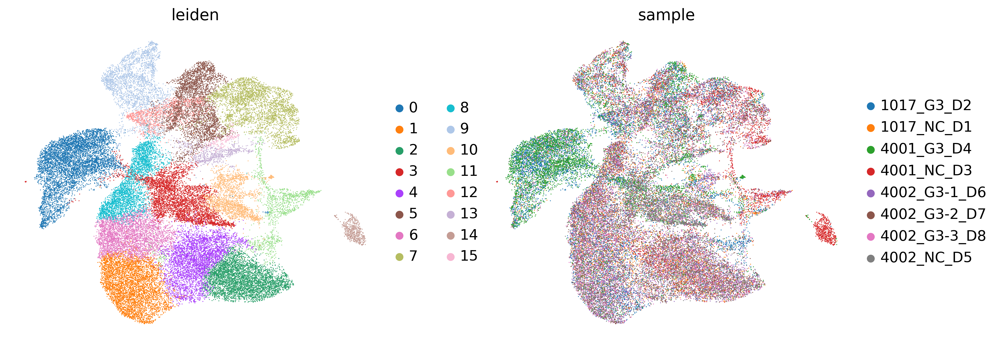

In [5]:
sc.pl.umap(
    query_adata,
    color= ["leiden", "sample"],
    # legend_loc="on data",
    # show=False,  # This prevents the plot from blocking execution
)

In [ ]:
# sc.pp.neighbors(query_adata, use_rep="X_pca")
# sc.tl.leiden(query_adata, resolution=0.8, key_added="leiden_pca_rss_80")

<positron-console-cell-8>:2: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.


In [6]:
query_adata.obs 

,sample,cell_line,genome,genotype,pair,batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,...,pct_counts_ribo,soupx_contamination,soupx_sample,doublet_method,doublet_score,predicted_doublet,S_score,G2M_score,phase,leiden
1017_G3_D2_AAACCCAAGACCAAGC-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2500,7.824446,4184,8.339262,...,1.099426,0.048,1017_G3_D2,Scrublet,0.043744,False,0.061389,-0.089042,S,10
1017_G3_D2_AAACCCAAGAGCATTA-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2080,7.640604,4250,8.354910,...,14.235294,0.048,1017_G3_D2,Scrublet,0.016845,False,0.013717,-0.111290,S,0
1017_G3_D2_AAACCCAAGGGAGGGT-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,1344,7.204149,2043,7.622664,...,11.747430,0.048,1017_G3_D2,Scrublet,0.042578,False,-0.078056,-0.067402,G1,0
1017_G3_D2_AAACCCAAGTCAACAA-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2090,7.645398,3529,8.169053,...,9.946160,0.048,1017_G3_D2,Scrublet,0.038250,False,-0.143950,-0.046145,G1,0
1017_G3_D2_AAACCCAAGTGTCATC-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,1498,7.312553,2344,7.760041,...,12.414676,0.048,1017_G3_D2,Scrublet,0.043744,False,-0.100224,-0.102793,G1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4002_NC_D5_TTTGTTGTCCTAGAGT-1,4002_NC_D5,4002_NC_D5,sloth,WT,stem_4002BM,4002_NC_D5,1355,7.212294,1953,7.577634,...,0.614439,0.020,4002_NC_D5,Scrublet,0.032654,False,-0.067278,-0.134569,G1,3
4002_NC_D5_TTTGTTGTCCTTCTAA-1,4002_NC_D5,4002_NC_D5,sloth,WT,stem_4002BM,4002_NC_D5,4602,8.434464,12441,9.428833,...,14.709429,0.020,4002_NC_D5,Scrublet,0.028244,False,-0.080320,-0.139772,G1,5
4002_NC_D5_TTTGTTGTCGAGATAA-1,4002_NC_D5,4002_NC_D5,sloth,WT,stem_4002BM,4002_NC_D5,4680,8.451267,11466,9.347229,...,11.913483,0.020,4002_NC_D5,Scrublet,0.043699,False,-0.187902,-0.122555,G1,6
4002_NC_D5_TTTGTTGTCGATTCCC-1,4002_NC_D5,4002_NC_D5,sloth,WT,stem_4002BM,4002_NC_D5,4263,8.357963,12474,9.431482,...,3.350970,0.020,4002_NC_D5,Scrublet,0.104391,False,-0.134820,-0.139384,G1,11


In [7]:
query_adata.obs.leiden.value_counts()

leiden
0     5759
1     4539
2     4056
3     4019
4     3881
5     3406
6     3377
7     3253
8     3164
9     2539
10    1958
11    1366
12    1172
13     766
14     548
15     194
Name: count, dtype: int64

#### 4. Marker Snapseed-based annotations 

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


1017_G3_D2_AAACCCAAGACCAAGC-1    10
1017_G3_D2_AAACCCAAGAGCATTA-1     0
1017_G3_D2_AAACCCAAGGGAGGGT-1     0
1017_G3_D2_AAACCCAAGTCAACAA-1     0
1017_G3_D2_AAACCCAAGTGTCATC-1     0
                                 ..
4002_NC_D5_TTTGTTGTCCTAGAGT-1     3
4002_NC_D5_TTTGTTGTCCTTCTAA-1     5
4002_NC_D5_TTTGTTGTCGAGATAA-1     6
4002_NC_D5_TTTGTTGTCGATTCCC-1    11
4002_NC_D5_TTTGTTGTCGCCGTGA-1     2
Name: leiden, Length: 43997, dtype: str
Index(['0', '1', '10', '11', '12', '13', '14', '15', '2', '3', '4', '5', '6',
       '7', '8', '9'],
      dtype='str', name='leiden')
Leiden clusters without assignments:
set()
                              leiden               snap_level_1  \
1017_G3_D2_AAACCCAAGACCAAGC-1     10  choroid_plexus_epithelium   
1017_G3_D2_AAACCCAAGAGCATTA-1      0                     neuron   
1017_G3_D2_AAACCCAAGGGAGGGT-1      0                     neuron   
1017_G3_D2_AAACCCAAGTCAACAA-1      0                     neuron   
1017_G3_D2_AAACCCAAGTGTCATC-1      0               

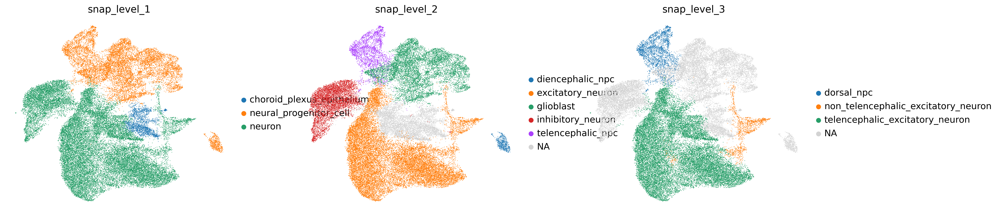

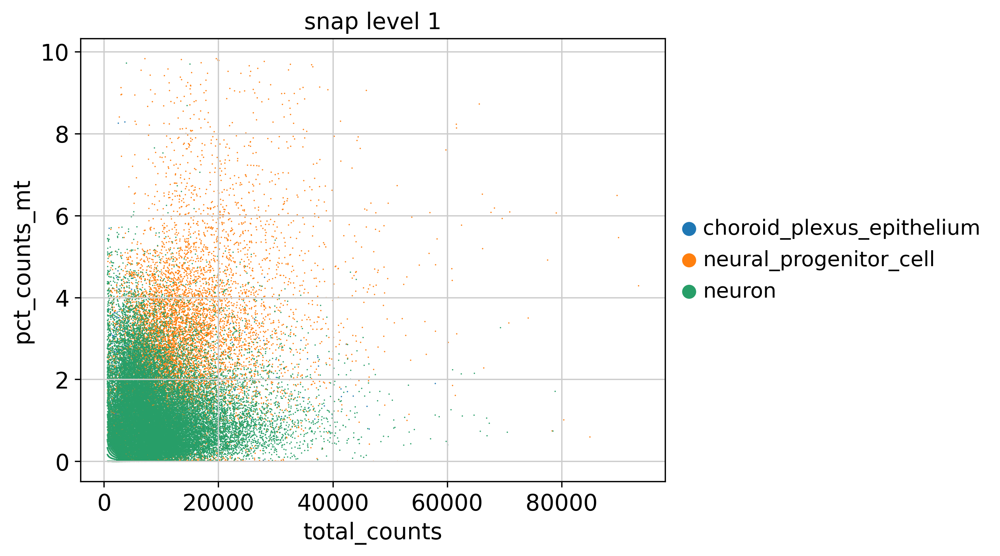

CellRank analysis complete.


In [ ]:
assignments = snap.annotate_hierarchy(query_adata, marker_hierarchy, group_name="leiden") 

# Check which leiden clusters don't have assignments
leiden_values = query_adata.obs["leiden"].astype(str)
available_assignments = assignments["assignments"].index
print(leiden_values)
print(available_assignments)

print("Leiden clusters without assignments:")
print(set(leiden_values) - set(available_assignments))

# Filter to only valid leiden values
valid_mask = leiden_values.isin(available_assignments)

# Get assignments only for valid leiden clusters
cell_assign = assignments["assignments"].loc[leiden_values[valid_mask], :].copy()

# Merge back to original size, filling missing clusters with "Unassigned"
cell_assign_full = pd.DataFrame(
    index=query_adata.obs.index,
    columns=cell_assign.columns,
    data="Unassigned"
)
cell_assign_full.loc[valid_mask, :] = cell_assign.values

# Use the full assignment
query_adata.obs["snap_level_1"] = cell_assign_full["level_1"].values
query_adata.obs["snap_level_2"] = cell_assign_full["level_2"].values
query_adata.obs["snap_level_3"] = cell_assign_full["level_3"].values

print(query_adata.obs[["leiden", "snap_level_1", "snap_level_2", "snap_level_3"]])

axes = sc.pl.umap(
    query_adata,
    color=["snap_level_1", "snap_level_2", "snap_level_3"],
    show=False,  # This prevents the plot from blocking execution
)

# Access the underlying figure from the first axis and save it
axes[0].get_figure().savefig(UMAP_PDF, bbox_inches="tight")
plt.show()

ax = sc.pl.scatter(
    query_adata,
    x="total_counts",  # Replace with your actual variable
    y="pct_counts_mt",  # Replace with your actual variable
    color="snap_level_1",
    show=False,
)
SCATTER_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_HNOCA_annotation_scatter.pdf"
# Save the scatter plot figure cleanly
ax.get_figure().savefig(SCATTER_PDF, bbox_inches="tight")

# Display inline for your Jupyter Notebook / HTML export
plt.show()

print("CellRank analysis complete.")

#### 5. HNOCA annotations-based label transfer using scANVI

In [ ]:
# 1. Lean model-input object holding raw counts only
counts = query_adata.layers["counts"]
v = counts.data if hasattr(counts, "data") else np.asarray(counts).ravel()
assert np.isfinite(v).all() and (v >= 0).all() and np.allclose(v, np.round(v)), "not raw integer counts"

query_ref = anndata.AnnData(
    X=counts.copy(),
    obs=pd.DataFrame(index=query_adata.obs_names),
    var=pd.DataFrame(index=query_adata.var_names),
)
# query_ref.obs["batch"] = "query_" + query_adata.obs["cell_line"].astype(str)   # real per-cell values, prefixed to avoid clashing with reference batches
query_ref.obs["batch"] = query_adata.obs["batch"].astype(str)   # real per-cell values, prefixed to avoid clashing with reference batches
query_ref.obs["annot_level_1"] = "Unknown"

# 2. Subset and zero-pad to the reference genes, without touching query_adata
query_ref = scvi.model.SCANVI.prepare_query_anndata(query_ref, REF_MODEL_DIR, inplace=False)
if "counts" not in query_ref.layers:
    query_ref.layers["counts"] = query_ref.X.copy()          # covers a reference registered on layer="counts"

# 3. Surgery model, plus a check before training
query_scanvi_model = scvi.model.SCANVI.load_query_data(query_ref, REF_MODEL_DIR)

# 4. Train
print("CUDA available:", torch.cuda.is_available())
query_scanvi_model.train(max_epochs=MAX_EPOCHS, plan_kwargs={"weight_decay": 0.0}, early_stopping=True)

# 5. Predict once, write results back to the full object
soft = query_scanvi_model.predict(query_ref, soft=True)
query_adata.obs["predicted_label"] = soft.idxmax(axis=1).reindex(query_adata.obs_names).astype("category")
query_adata.obs["prediction_confidence"] = soft.max(axis=1).reindex(query_adata.obs_names)
z = pd.DataFrame(query_scanvi_model.get_latent_representation(query_ref), index=query_ref.obs_names)
query_adata.obsm["X_scANVI"] = z.reindex(query_adata.obs_names).to_numpy()

# Now you can check for NaNs after training
assert np.isfinite(z.values).all(), "NaN latent after training"

print(query_adata.obs["predicted_label"].value_counts())

INFO     File                                                                   
         /dcs04/lieber/hwanglab/Arun/bmaher/Annotations/HNOCA_annotation/archmap
         /saved_scanvi_reference_model/model.pt already downloaded              
INFO     Found 93.4% reference vars in query data.                              
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Not Trained
Model's adata is minified?: False


#### 6. Transfer the other annotation labels based on Nearest Neighbors

In [ ]:
transfer_labels = ["annot_level_1", "annot_level_2", "annot_region_rev2", "annot_level_3_rev2", "annot_ntt_rev2", "annot_level_4_rev2"]

for label in transfer_labels:
    if label not in ref_adata.obs:
        raise KeyError(f"{label} not found in reference AnnData.")

# Use it
z_query = query_scanvi_model.get_latent_representation(query_ref)
z_ref = query_scanvi_model.get_latent_representation(ref_adata)

print("\nTransferring HNOCA annotations...")
knn = NearestNeighbors(
    n_neighbors=N_NEIGHBORS,
    metric="euclidean",
    algorithm="auto",
    n_jobs=-1
)
knn.fit(z_ref)

print("Finding reference neighbors...")
all_indices = []
for start in range(0, z_query.shape[0], QUERY_BATCH_SIZE):
    end = min(start + QUERY_BATCH_SIZE, z_query.shape[0])
    print(f"  Query cells {start:,} - {end:,}")
    _, idx = knn.kneighbors(z_query[start:end])
    all_indices.append(idx)
neighbor_indices = np.vstack(all_indices)

for label in transfer_labels:
    print(f"  {label}")
    ref_labels = ref_adata.obs[label].astype(str).to_numpy()
    transferred = []
    for idx in neighbor_indices:
        labels = ref_labels[idx]
        transferred.append(pd.Series(labels).value_counts().index[0])
    query_adata.obs[label] = pd.Categorical(transferred)

print(f"✓ Transferred {len(transfer_labels)} labels")


Transferring HNOCA annotations...
Finding reference neighbors...
  Query cells 0 - 2,000
  Query cells 2,000 - 4,000
  Query cells 4,000 - 6,000
  Query cells 6,000 - 8,000
  Query cells 8,000 - 10,000
  Query cells 10,000 - 12,000
  Query cells 12,000 - 14,000
  Query cells 14,000 - 16,000
  Query cells 16,000 - 18,000
  Query cells 18,000 - 20,000
  Query cells 20,000 - 22,000
  Query cells 22,000 - 24,000
  Query cells 24,000 - 26,000
  Query cells 26,000 - 28,000
  Query cells 28,000 - 30,000
  Query cells 30,000 - 32,000
  Query cells 32,000 - 34,000
  Query cells 34,000 - 36,000
  Query cells 36,000 - 38,000
  Query cells 38,000 - 40,000
  Query cells 40,000 - 42,000
  Query cells 42,000 - 43,997
  annot_level_1
  annot_level_2
  annot_region_rev2
  annot_level_3_rev2
  annot_ntt_rev2
  annot_level_4_rev2
✓ Transferred 6 labels
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gen

In [30]:
query_adata.var.shape

(34437, 16)

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
for label in transfer_labels:
    print(f"\n{label}:")
    print(query_adata.obs[label].value_counts())

#### 7. Compute SCANVI UMAP

In [ ]:
print("\nComputing SCANVI UMAP...")
sc.pp.neighbors(query_adata, use_rep="X_scANVI", n_neighbors=15)
sc.tl.umap(query_adata, min_dist=0.3)


Computing SCANVI UMAP...
computing neighbors
    finished (0:00:20)
computing UMAP
    finished (0:00:15)
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [32]:
query_adata.raw.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 170569985 stored elements and shape (43997, 34437)>

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [34]:
import numpy as np, scipy.sparse as sp

rng = np.random.default_rng(0)
idx = np.sort(rng.choice(query_adata.n_obs, 2000, replace=False))
dense = lambda M: M.toarray() if sp.issparse(M) else np.asarray(M)

print("X:", query_adata.shape, "| raw:", query_adata.raw.shape, "| layers:", list(query_adata.layers))
print("raw genes cover X genes:", query_adata.var_names.isin(query_adata.raw.var_names).all())

X = dense(query_adata.X[idx])
print("\nX      sparse:", sp.issparse(query_adata.X), "| min/max:", X.min().round(2), X.max().round(2),
      "| frac == 10:", (X == 10).mean().round(4),
      "| median gene mean/std:", np.median(X.mean(0)).round(3), np.median(X.std(0)).round(3))

C = dense(query_adata.layers["counts"][idx])
print("counts integer:", np.allclose(C, np.round(C)), "| min/max:", C.min(), C.max())

R = dense(query_adata.raw.X[idx])
print("raw.X  min/max:", R.min().round(2), R.max().round(2),
      "| median expm1 row sum:", np.median(np.expm1(R).sum(1)).round(1))

X: (43997, 34437) | raw: (43997, 34437) | layers: ['counts', None]
raw genes cover X genes: True

X      sparse: False | min/max: -7.86 10.0 | frac == 10: 0.0011 | median gene mean/std: -0.01 0.891
counts integer: True | min/max: 0.0 3017.0
raw.X  min/max: 0.0 8.04 | median expm1 row sum: 10000.0
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [ ]:
# Save the log-normalized expression values in a new layer for downstream analysis
query_adata.layers["lognorm"] = query_adata.raw[:, query_adata.var_names].X.copy()

## Matrix	 | Result	 |  Verdict
# .X	| dense, min -7.86, max 10.0, 0.11% of values at exactly 10, median gene mean -0.01 and std 0.89  |  z-scored and clipped at 10
# .layers["counts"]	| integers, 0 to 3017  |  raw counts
# .raw.X	| min 0, max 8.04, median expm1 row sum 10000  |  log-normalized (normalize_total to 1e4, then log1p)

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


#### 8. Save the annotated query AnnData to disk

In [45]:
query_adata.write_h5ad(OUT_H5AD)
print(f"\nSaved annotated query AnnData to {OUT_H5AD}")


Saved annotated query AnnData to /dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_HNOCA_annotated.h5ad
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [38]:
query_adata.obs.head()

,sample,cell_line,genome,genotype,pair,batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,...,snap_level_2,snap_level_3,predicted_label,prediction_confidence,annot_level_1,annot_level_2,annot_region_rev2,annot_level_3_rev2,annot_ntt_rev2,annot_level_4_rev2
1017_G3_D2_AAACCCAAGACCAAGC-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2500,7.824446,4184,8.339262,...,NaN,NaN,Neuron,0.999431,Neuron,Dorsal Telencephalic Neuron,Dorsal telencephalon,Dorsal Telencephalic Neuron,NT-VGLUT,Dorsal Telencephalic Neuron NT-VGLUT
1017_G3_D2_AAACCCAAGAGCATTA-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2080,7.640604,4250,8.354910,...,inhibitory_neuron,NaN,Neuron,1.000000,Neuron,Ventral Telencephalic Neuron,Ventral telencephalon,Ventral Telencephalic Neuron,NT-GABA,Ventral Telencephalic Neuron NT-GABA
1017_G3_D2_AAACCCAAGGGAGGGT-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,1344,7.204149,2043,7.622664,...,inhibitory_neuron,NaN,Neuron,1.000000,Neuron,Ventral Telencephalic Neuron,Ventral telencephalon,Ventral Telencephalic Neuron,NT-GABA,Ventral Telencephalic Neuron NT-GABA
1017_G3_D2_AAACCCAAGTCAACAA-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,2090,7.645398,3529,8.169053,...,inhibitory_neuron,NaN,Neuron,1.000000,Neuron,Ventral Telencephalic Neuron,Ventral telencephalon,Ventral Telencephalic Neuron,NT-GABA,Ventral Telencephalic Neuron NT-GABA
1017_G3_D2_AAACCCAAGTGTCATC-1,1017_G3_D2,1017_G3_D2,otter,KO,stem_1017BM,1017_G3_D2,1498,7.312553,2344,7.760041,...,inhibitory_neuron,NaN,Neuron,1.000000,Neuron,Ventral Telencephalic Neuron,Ventral telencephalon,Ventral Telencephalic Neuron,NT-GABA,Ventral Telencephalic Neuron NT-GABA


ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


#### 9. UMAP's and celltype proportions

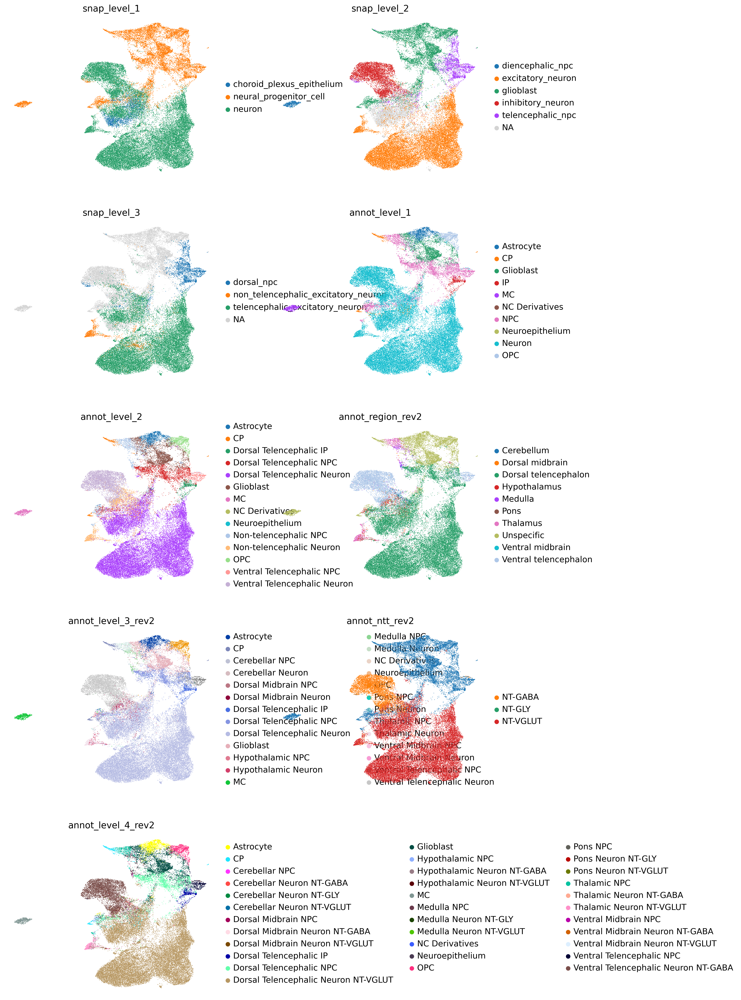

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [28]:
new_transfer_labels = ["snap_level_1", "snap_level_2", "snap_level_3"] + transfer_labels
# sc.pl.umap(query_adata, color=new_transfer_labels, ncols=2)

axes = sc.pl.umap(
    query_adata,
    color=new_transfer_labels, ncols=2,
    show=False,  # This prevents the plot from blocking execution
)
UMAP_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_advanced_HNOCA_annotation_UMAPs.pdf"
# Access the underlying figure from the first axis and save it
axes[0].get_figure().savefig(UMAP_PDF, bbox_inches="tight")
plt.show()


In [29]:
UMAP_PDF="/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_advanced_HNOCA_annotation_UMAPs_v2.pdf"
plot_labels = [
    "annot_level_1",
    "snap_level_1",
    "snap_level_2",
    "snap_level_3",
    
    "annot_level_2",
    "annot_level_3_rev2",
    
    # "annot_ntt_rev2",
    # "annot_level_4_rev2",
    # "annot_region_rev2",
]
plot_titles = [
    "HNOCA annot_level_1",
    "Snapseed level 1",
    "Snapseed level 2",
    "Snapseed level 3",

    "HNOCA annot_level_2",
    "HNOCA annot_level_3_rev2",

    # "HNOCA annot_ntt_rev2",
    # "HNOCA annot_level_4_rev2",
    # "HNOCA annot_region_rev2",
]
print("\nCreating UMAP PDF...")
with PdfPages(UMAP_PDF) as pdf:
    fig, axes = plt.subplots(3, 2, figsize=(18, 28))
    axes = axes.flatten()
    for ax, label, title in zip(axes, plot_labels, plot_titles):
        if label in query_adata.obs:
            sc.pl.umap(query_adata, color=label, ax=ax, show=False, frameon=False, title=title, legend_loc="right margin")
        else:
            ax.axis("off")
            ax.set_title(f"{title} not available")
    plt.tight_layout()
    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

# ============================================================
# 18. Save annotated query
# ============================================================
print("\nSaving annotated query...")
# query_adata.write_h5ad(OUT_H5AD)
print("\nDONE")
print("Annotated query:", OUT_H5AD)
print("UMAP PDF:", UMAP_PDF)


Creating UMAP PDF...

Saving annotated query...

DONE
Annotated query: /dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_HNOCA_annotated.h5ad
UMAP PDF: /dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/GRIA3_maher_advanced_HNOCA_annotation_UMAPs_v2.pdf
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [39]:
query_adata.obs.groupby("sample")["total_counts"].sum()
sample_summary = query_adata.obs.groupby("sample")["total_counts"].agg(
    cell_count="count", total_sum="sum"
)
print(sample_summary)

print(query_adata.layers['counts'].shape)


              cell_count  total_sum
sample                             
1017_G3_D2          9150   71935658
1017_NC_D1          4120   33999333
4001_G3_D4          6893   60560463
4001_NC_D3          3791   73928093
4002_G3-1_D6        5569   63357219
4002_G3-2_D7        5396   54875365
4002_G3-3_D8        4171   31435205
4002_NC_D5          4907   46222692
(43997, 34437)
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!

--- Proportion Differences: annot_level_1 ---
                 baseline_props  mean_props_KO  mean_props_WT  prop_ratio  \
clusters                                                                    
Astrocyte              0.027638       0.025172       0.033672    0.747549   
CP                     0.010342       0.003779       0.029668    0.127393   
Glioblast              0.067914       0.065505       0.062595    1.046500   
IP                     0.010478       0.010404       0.014197    0.732854   
MC                     0.012569       0.000600       0.046648    0.012870   
NC Derivatives         0.000045       0.000036       0.000088    0.408440   
NPC                    0.107712       0.104305       0.118415    0.880847   
Neuroepithelium        0.000159       0.000145       0.000149    0.972987   
Neuron                 0.741801       0.766335       0.684626    1.119347   
OPC                    0.021342   

/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:347: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out.results[col].fillna(0, inplace=True)
/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:349: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained 

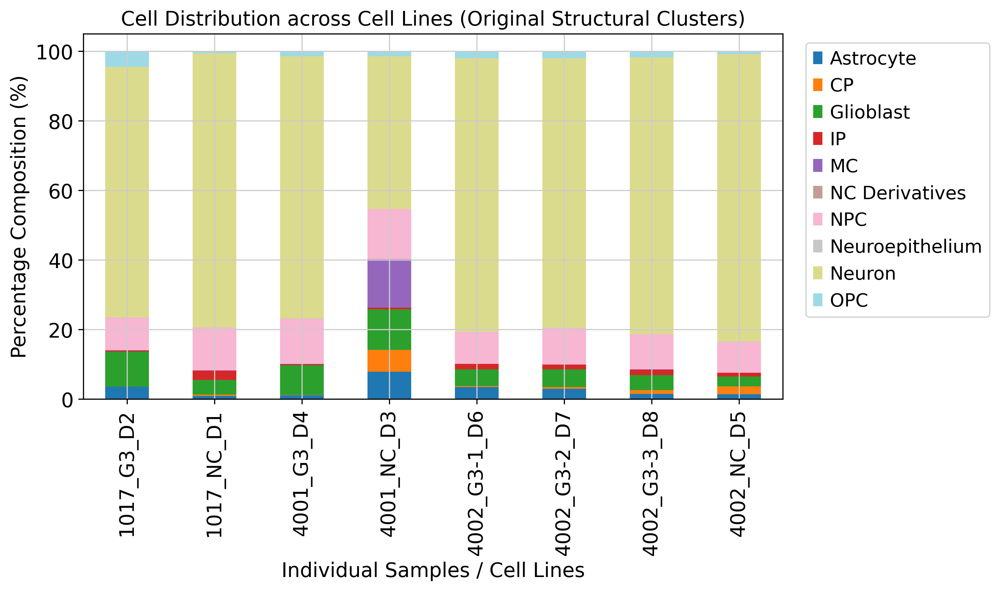

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [41]:
# from scanpro import scanpro

# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='annot_level_1', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: annot_level_1 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['annot_level_1'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/scanpro_proportions_annot_level_1.pdf', bbox_inches='tight')
plt.show()


[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
--- Proportion Differences: annot_level_2 ---
                              baseline_props  mean_props_KO  mean_props_WT  \
clusters                                                                     
Astrocyte                           0.027638       0.025172       0.033672   
CP                                  0.010546       0.003856       0.030176   
Dorsal Telencephalic IP             0.010728       0.010675       0.014446   
Dorsal Telencephalic NPC            0.056549       0.057856       0.058161   
Dorsal Telencephalic Neuron         0.569289       0.584170       0.621134   
Glioblast                           0.070505       0.067673       0.065377   
MC                                  0.012569       0.000600       0.046648   
NC Derivatives                      0.000045       0.000036       0.000088   
Neuroepithelium                     0.000182       0.000167       0.000149   
Non-telencephalic NPC   

/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:347: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out.results[col].fillna(0, inplace=True)
/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:349: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained 

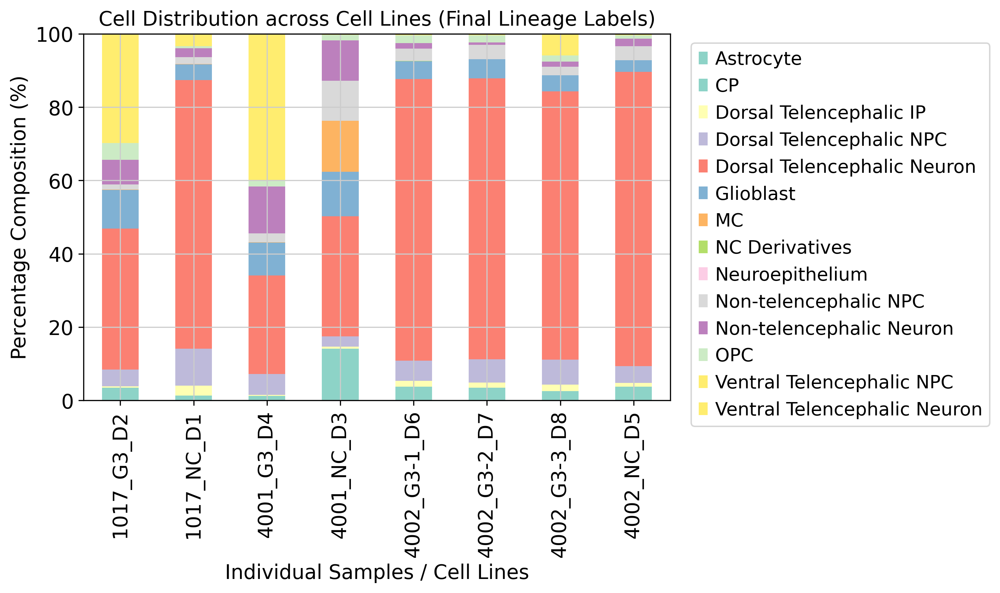

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [42]:
from scanpro import scanpro

# 1. Calculate proportions and differential statistics via scanpro
out_final = scanpro(
    query_adata, 
    clusters_col='annot_level_2', 
    conds_col='genotype', 
    samples_col='sample'
)

# 2. Display the statistical results summary
print("--- Proportion Differences: annot_level_2 ---")
print(out_final.results)

# 3. Generate Stacked Bar Plot via Pandas/Matplotlib
# Grouping counts systematically by sample to compute independent relative percentages
props_final = pd.crosstab(query_adata.obs['sample'], query_adata.obs['annot_level_2'], normalize='index') * 100

ax = props_final.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set3')
plt.title('Cell Distribution across Cell Lines (Final Lineage Labels)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/scanpro_proportions_annot_level_2.pdf', bbox_inches='tight')
plt.show()

[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!

--- Proportion Differences: snap_level_1 ---
                           baseline_props  mean_props_KO  mean_props_WT  \
clusters                                                                  
choroid_plexus_epithelium        0.044503       0.038439       0.059265   
neural_progenitor_cell           0.269973       0.250782       0.310058   
neuron                           0.685524       0.710778       0.630677   

                           prop_ratio  t_statistics  p_values  \
clusters                                                        
choroid_plexus_epithelium    0.648601     -1.009116  0.326292   
neural_progenitor_cell       0.808824     -0.534801  0.599333   
neuron                       1.127008      0.882068  0.389368   

                           adjusted_p_values  
clusters                                      
choroid_plexus_epithelium           0.584051  
neural_progenitor_cell              0.5

/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:347: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out.results[col].fillna(0, inplace=True)
/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:349: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained 

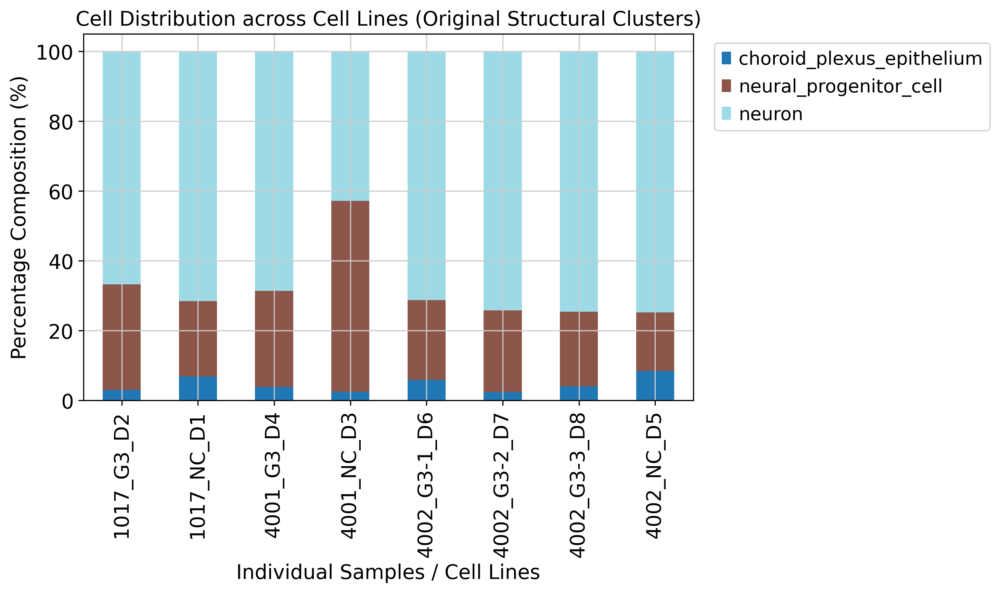

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [43]:
# from scanpro import scanpro

# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='snap_level_1', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: snap_level_1 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['snap_level_1'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/scanpro_proportions_snap_level_1.pdf', bbox_inches='tight')
plt.show()


[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!

--- Proportion Differences: snap_level_2 ---
                   baseline_props  mean_props_KO  mean_props_WT  prop_ratio  \
clusters                                                                      
diencephalic_npc         0.012455       0.000764       0.048137    0.015878   
excitatory_neuron        0.463282       0.543476       0.626364    0.867668   
glioblast                0.199809       0.215802       0.248138    0.869687   
inhibitory_neuron        0.130895       0.171872       0.017651    9.737311   
telencephalic_npc        0.057708       0.068085       0.059710    1.140259   
NaN                           NaN            NaN            NaN         NaN   

                   t_statistics  p_values  adjusted_p_values  
clusters                                                      
diencephalic_npc      -1.078325  0.317091           0.654101  
excitatory_neuron     -0.533876  0.610165           0.654101

/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:347: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out.results[col].fillna(0, inplace=True)
/users/ahanuman/.local/lib/python3.12/site-packages/scanpro/scanpro.py:349: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained 

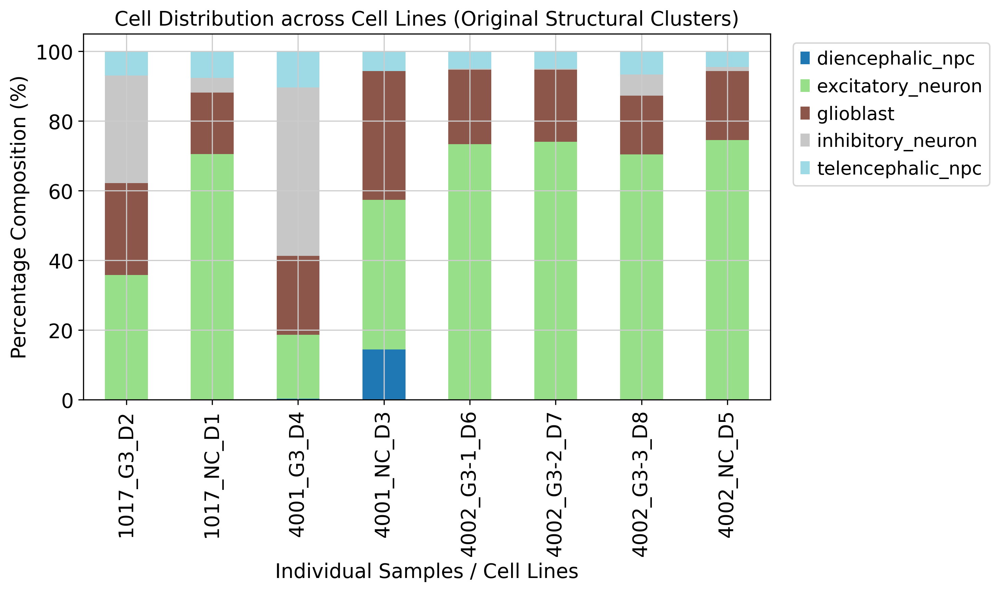

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, 
dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [44]:
# 1. Calculate statistical shifts on structural annotations
out_annot = scanpro(
    query_adata, 
    clusters_col='snap_level_2', 
    conds_col='genotype', 
    samples_col='sample'
)

print("\n--- Proportion Differences: snap_level_2 ---")
print(out_annot.results)

# 2. Generate Stacked Bar Plot for original labels
props_annot = pd.crosstab(query_adata.obs['sample'], query_adata.obs['snap_level_2'], normalize='index') * 100

ax2 = props_annot.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Cell Distribution across Cell Lines (Original Structural Clusters)')
plt.xlabel('Individual Samples / Cell Lines')
plt.ylabel('Percentage Composition (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('/dcs04/lieber/hwanglab/Arun/bmaher/GRIA3_maher/3_analysis/02_cell_annotations/scanpro_proportions_snap_level_2.pdf', bbox_inches='tight')
plt.show()


#### Reproducibility information

In [71]:
from prettytable import PrettyTable
from print_versions import print_versions
from platform import python_version, uname

ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False


In [72]:
# Create a PrettyTable object for the system information
sys_info_table = PrettyTable()
sys_info_table.field_names = ["Attribute", "Value"]

# Add system information to the table
sys_info_table.add_row(["Python Version", python_version()])
uname_info = uname()
sys_info_table.add_row(["System", uname_info.system])
sys_info_table.add_row(["Node Name", uname_info.node])
sys_info_table.add_row(["Release", uname_info.release])
sys_info_table.add_row(["Version", uname_info.version])
sys_info_table.add_row(["Machine", uname_info.machine])
sys_info_table.add_row(["Processor", uname_info.processor])

# Print the system information table
print("System Information:")
print(sys_info_table)

System Information:
+----------------+----------------------------------------------------+
|   Attribute    |                       Value                        |
+----------------+----------------------------------------------------+
| Python Version |                      3.12.14                       |
|     System     |                       Linux                        |
|   Node Name    |               compute-117.cm.cluster               |
|    Release     |            5.14.0-427.13.1.el9_4.x86_64            |
|    Version     | #1 SMP PREEMPT_DYNAMIC Wed May 1 19:11:28 UTC 2024 |
|    Machine     |                       x86_64                       |
|   Processor    |                       x86_64                       |
+----------------+----------------------------------------------------+
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: 

In [73]:
print_versions(globals())

/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:10: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if getattr(m, "__version__", None):
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  versions[m.__name__] = m.__version__
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:10: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if getattr(m, "__version__", None):
/users/ahanuman/.conda/envs/hnoca_gpu/lib/python3.12/site-packages/print_versions/versions.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  versions[m.__name__] = m.__version__


pandas==3.0.1
anndata==0.13.3.post0
numpy==2.5.3
scanpy==1.12.4
scvi==1.5.1
torch==2.6.0+cu124
matplotlib==3.10.8
flax==0.12.9
hnoca==0.2.2.dev5+g19a8b06ce
prettytable==3.18.0
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
ScanVI Model with the following params: 
unlabeled_category: Unknown, n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb
Training status: Trained
Model's adata is minified?: False
